# Directional Coupler — Single-Domain FDTD

Standard directional coupler, brute-force reference FDTD via meep — the WHOLE
coupler (input S-bends, straight coupled-pair region, output S-bends) sits in a
single simulation domain. Same device as the hybrid notebook
(`directional_coupler_hybrid`), at ONE hard-coded coupling length.

```
    "in"  ___                                      ____  "through"
             \
              \__________________________________/        (coupling gap)
              /                                    \
    ___      /                                      \___  "cross"
   "isolated"

    |<- bend_length ->|<--- coupling_length --->|<- bend_length ->|
```

One broadband GaussianSource pulse excites the fundamental mode of the "in" arm;
DFT mode monitors at the two output arms extract the complex transmission at
every wavelength in one run, so the entire wavelength sweep costs exactly
**1 FDTD simulation**.

Contrast with the hybrid notebook, which decomposes the same device into
[FDTD bend | EME coupling region | FDTD bend]: here nothing is decomposed or
approximated by a truncated mode basis — every scattering/radiation path in the
real structure is captured in full, making this the validation reference for the
hybrid result at this coupling length. The price is that the domain contains the
entire coupling_length of essentially-uniform waveguide — the exact region EME
propagates for free — so the run cost grows with coupling_length and sweeping it
means one full FDTD run *per length* (vs. the hybrid notebook's 201-length sweep
for the cost of one). Use FDTD to spot-check; use the hybrid to explore.

The coupling length is hard-coded to the ~50:50 (3 dB) splitting length for this
cross-section — the kind of value you'd read off the hybrid notebook's
coupling-length sweep plot and then verify here.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from beef import DirectionalCoupler, FDTDSolver, SOI_220, plot_fdtd_geometry

In [2]:
# Global simulation parameters
RESOLUTION = 40.0   # mesh resolution (pixels/um)
WL_MIN = 1.50       # wavelength sweep start (um)
WL_MAX = 1.60       # wavelength sweep end (um)
N_WL = 11           # number of wavelength points

# The 3 dB length for this cross-section, read off the full-device FDTD ground
# truth (directional_coupler_validation.md item 5), whose band-mean
# cross/(cross+through) crosses 0.5 at 15.129 um. The beta-calibrated hybrid
# independently lands on 15.15 um, its nearest sampled length, 0.14% away.
#
# WAS 13.5 um until 2026-07-28, and that was wrong: the reference gives
# cross/(cross+through) = 0.4318 there, i.e. a 43:57 splitter, not 3 dB. It came
# from the pre-fix hybrid sweep, which reported L_50 = 13.65 um *with the
# wavelength axis reversed* (item 1), and survived both that fix and item 5's
# ground-truth rebuild because nothing rechecked it. See item 14.
COUPLING_LENGTH = 15.13   # um, hard-coded — the 3 dB length; see above

In [3]:
# Persistent on-disk simulation cache (see beef/cache/) — a solve_section()
# call whose config matches a prior cached run loads that result instead of
# re-simulating. Assumes this notebook runs from its own directory
# (examples/directional_coupler/notebooks/), matching directional_coupler_fdtd.py's save_dir.
save_dir = os.path.abspath(os.path.join("..", "..", "example_sim_cache"))

# Notebook-only: never actually run a simulation here, only render from an
# already-populated cache — the script populates save_dir first; this
# notebook is for docs/rendering and must not silently kick off a fresh
# (possibly multi-hour) run. Raises CacheMissError if something isn't cached.
CACHE_ONLY = True

In [4]:
# 1. Geometry — identical to directional_coupler_hybrid.ipynb except that
#    coupling_length is pinned instead of swept.
dc = DirectionalCoupler(
    waveguide_width=0.45,             # single-mode strip width (um)
    gap=0.25,                         # coupling-region edge-to-edge gap (um)
    coupling_length=COUPLING_LENGTH,  # straight parallel interaction length (um)
    bend_length=9.0,                  # horizontal extent of each S-bend (um)
    waveguide_offset=3.0,             # far-end centre-to-centre port pitch (um)
    bend_type="euler",                # "euler" (cubic-Bezier S-bend) or "circular" (matched arcs)
    waveguide_height=0.22,            # Si layer thickness (um) — SOI_220
)
print(f"Directional coupler total length: {dc.total_length:.2f} um "
      f"(coupling length {dc.coupling_length:.2f} um, "
      f"coupling pitch {dc.coupling_pitch:.3f} um, far pitch {dc.waveguide_offset:.2f} um)")

Directional coupler total length: 31.50 um (coupling length 13.50 um, coupling pitch 0.700 um, far pitch 3.00 um)


In [5]:
# 2. Configure the FDTD solver — one domain around the whole device.
#
#    The output arms sit at y = +-waveguide_offset/2 = +-1.5 um; each output
#    monitor is a half-domain window (3 um wide, from the shared y=0 axis to
#    the near PML edge) centered on its own arm, so each measures only its
#    arm's fundamental mode without reaching the other arm or the PML — the
#    same window the source/norm monitor get automatically from
#    DirectionalCoupler.source_aperture_at on the input side.
solver = FDTDSolver(
    res=RESOLUTION,
    sim_width=6.0,        # >= waveguide_offset + margin, so both arms sit inside PML clearance
    sim_height=1.5,
    dpml=0.5,
    source_margin=0.0,
    monitor_margin=0.25,
    three_d=True,       # full 3-D FDTD: real 220 nm Si core in oxide, PML on all six faces
    num_input_modes=1,
    num_output_modes=1,   # fundamental mode per output arm
    # Order fixes the SMatrix port names: out_0 = bottom arm ("through",
    # same arm as "in"), out_1 = top arm ("cross", the coupled arm).
    output_monitor_centers=[-1.5, +1.5],
    output_monitor_widths=[3.0, 3.0],
    material_stack=SOI_220,
    decay_tol=1e-11,
)

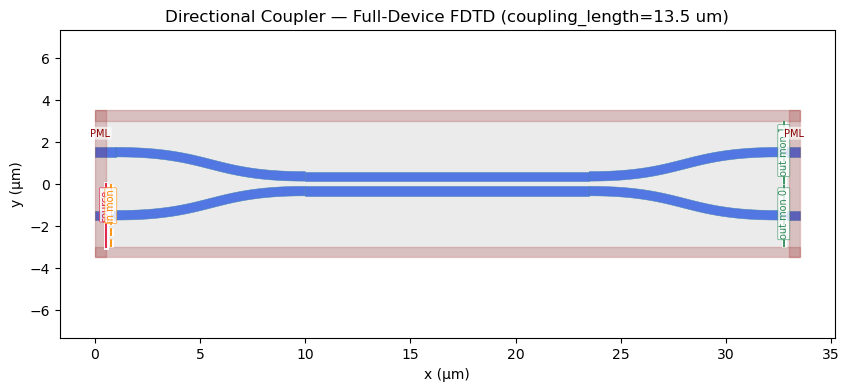

In [6]:
# 3. Geometry plot — the full single simulation domain: source + norm monitor
#    on the "in" arm (shrunk to the geometry's launch window), one output
#    monitor per arm, PML on all four sides.
plot_fdtd_geometry(
    dc, solver=solver,
    port="bot",   # bottom input arm = "in" (see DirectionalCoupler.input_ys)
    title=f"Directional Coupler — Full-Device FDTD (coupling_length={COUPLING_LENGTH:.1f} um)",
)
plt.show()

In [7]:
# 4. Wavelength sweep — a single broadband run. port="bot" excites the
#    fundamental TE mode of the "in" arm; the DFT monitors resolve all N_WL
#    wavelengths from that one pulse.
wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)
print(f"\nWavelength sweep: {wavelengths[0]:.3f} - {wavelengths[-1]:.3f} um "
      f"({len(wavelengths)} pts, single FDTD run)\n")

smat = solver.solve(dc, wavelengths, port="bot", input_mode=1, save_dir=save_dir, cache_only=CACHE_ONLY)
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength


Wavelength sweep: 1.500 - 1.600 um (11 pts, single FDTD run)

Using MPI version 4.1, 1 processes


ModuleNotFoundError: No module named 'feces'

In [ ]:
# 5. Print summary at the centre wavelength
T_through = smat.transmission(port="out_0", in_mode=1, out_mode=1)  # bottom arm, same as "in"
T_cross = smat.transmission(port="out_1", in_mode=1, out_mode=1)    # top arm, coupled
T_total = T_through + T_cross

wl_c = wavelengths[len(wavelengths) // 2]
idx = np.argmin(np.abs(wavelengths - wl_c))

print(f"Results at coupling_length = {COUPLING_LENGTH:.2f} um, wavelength = {wl_c:.3f} um:")
print(f"  Through output T = {T_through[idx]:.4f}  IL = {10*np.log10(max(T_through[idx],1e-20)):.2f} dB")
print(f"  Cross output   T = {T_cross[idx]:.4f}  IL = {10*np.log10(max(T_cross[idx],1e-20)):.2f} dB")
print(f"  Total          T = {T_total[idx]:.4f}  IL = {10*np.log10(max(T_total[idx],1e-20)):.2f} dB")
print(f"  Coupling ratio   = {T_cross[idx]/max(T_total[idx],1e-20):.3f}  "
      f"(0 = fully through, 1 = fully cross; ~0.5 expected at the 3 dB length)")

Results at coupling_length = 13.50 um, wavelength = 1.550 um:
  Through output T = 0.5759  IL = -2.40 dB
  Cross output   T = 0.4238  IL = -3.73 dB
  Total          T = 0.9997  IL = -0.00 dB
  Coupling ratio   = 0.424  (0 = fully through, 1 = fully cross; ~0.5 expected at the 3 dB length)


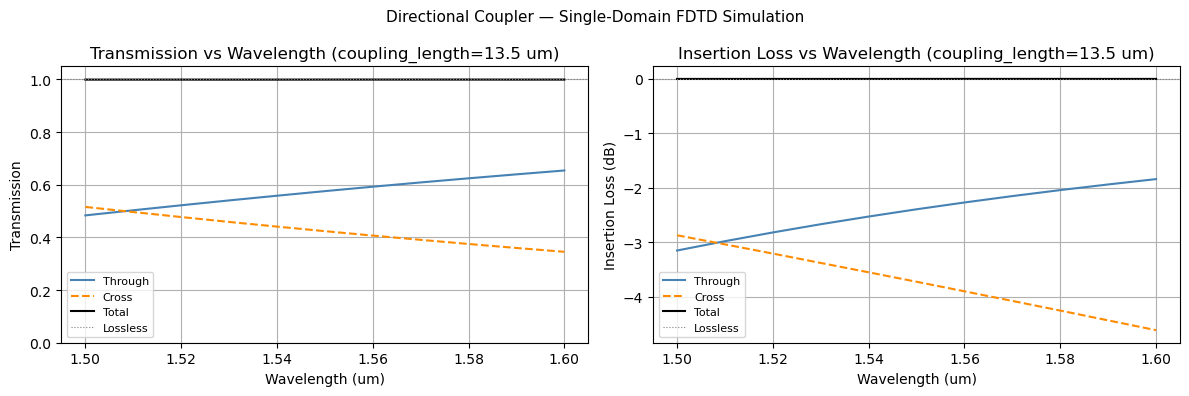

In [ ]:
# 6. Results plot — same two-panel layout as the hybrid notebook's results
#    plot, for side-by-side comparison.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wavelengths, T_through, label="Through", color="steelblue")
ax.plot(wavelengths, T_cross,   label="Cross",   color="darkorange", linestyle="--")
ax.plot(wavelengths, T_total,   label="Total",   color="k", lw=1.5)
ax.axhline(1.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title(f"Transmission vs Wavelength (coupling_length={COUPLING_LENGTH:.1f} um)")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1.05)

ax = axes[1]
IL_through = 10 * np.log10(np.clip(T_through, 1e-20, None))
IL_cross   = 10 * np.log10(np.clip(T_cross,   1e-20, None))
IL_total   = 10 * np.log10(np.clip(T_total,   1e-20, None))
ax.plot(wavelengths, IL_through, label="Through", color="steelblue")
ax.plot(wavelengths, IL_cross,   label="Cross",   color="darkorange", linestyle="--")
ax.plot(wavelengths, IL_total,   label="Total",   color="k", lw=1.5)
ax.axhline(0.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title(f"Insertion Loss vs Wavelength (coupling_length={COUPLING_LENGTH:.1f} um)")
ax.legend(fontsize=8)
ax.grid(True)

plt.suptitle("Directional Coupler — Single-Domain FDTD Simulation", fontsize=11)
plt.tight_layout()
plt.show()